# Monthly equity selection
DSA5205 Project 2 · Group 45

We studied whether a return model improved stock selection within a momentum–volatility screen. We compared four model families on the 2020–2021 validation set. The model selected from that comparison was evaluated against fixed benchmarks in 2022–2025.

## 1. Markets, data and timing

We used daily Yahoo Finance prices and volumes for US stocks in a current S&P 500 constituent snapshot. At each month-end close, we applied price, liquidity and coverage filters, required finite features, and kept up to 300 stocks by 20-session average dollar volume. A momentum–volatility double sort selected 30 candidates, with 3, 4 and 3 stocks from the low, middle and high volatility cells within each momentum group.

Features used data through the decision close. Trades took place at the next session open. The label was the adjusted-open return from entry to the next rebalance open.

| Portfolio | Role | Selection rule | Weighting |
|---|---|---|---|
| Ridge | Candidate model | Top 10 Ridge scores in the screened pool | Equal 10% |
| LASSO | Candidate model | Top 10 LASSO scores in the screened pool | Equal 10% |
| Random Forest | Candidate model | Top 10 Random Forest scores in the screened pool | Equal 10% |
| XGBoost | Candidate model | Top 10 XGBoost scores in the screened pool | Equal 10% |
| B1 | Momentum benchmark | Top 10 by 12–1 momentum in the full liquid pool | Equal 10% |
| B3 | Momentum benchmark | Top 10 by 12–1 momentum in the screened pool | Equal 10% |
| SPY | ETF benchmark | Buy and hold the S&P 500 ETF | Fully invested |
| QQQ | ETF benchmark | Buy and hold the Nasdaq-100 ETF | Fully invested |

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from run_primary_study import (
    build_data, compare_validation_strategies, evaluate_ridge, plot_results, record_model_selection,
)
from src.data_pipeline import chronological_splits, load_config, load_model_ready
from src.features import describe_features
from src.validation import run_validation

cfg = load_config()
REBUILD_DATA = False
if REBUILD_DATA:
    build_data(cfg)
display(describe_features())

,feature,description,screening_feature,forward_filled_in_pipeline
0,mom_21,21-session total return,False,True
1,mom_63,63-session total return,False,True
2,mom_126,126-session total return,False,True
3,mom_2_12,12-month return skipping the most recent month...,True,False
4,relative_mom_63,63-session return minus SPY 63-session return,False,True
5,vol_21,annualised 21-session realised volatility,False,True
6,vol_63,annualised 63-session realised volatility,True,False
7,beta_252,252-session rolling beta to SPY,False,True
8,drawdown_63,current price relative to its 63-session high,False,True
9,ma_ratio_50,price relative to its 50-session moving average,False,True


## 2. Training and validation

Prices from 2009 supplied the feature lookbacks. Before fitting the models, we set 2010–2019 for training, 2020–2021 for validation, and 2022–2025 for testing. The training and validation blocks included labels that had settled by their respective cutoffs. Ridge and LASSO used standardisers fitted on the training rows. Random Forest and XGBoost used the original feature scales.

All four models used the same 15 predictors, 30 candidates per decision, and adjusted-open return target. We evaluated 23 configurations across the four families and selected each family's hyperparameters by validation MSE. Rank IC averages the monthly Spearman correlations between scores and realised returns across all 30 candidates. The comparison also reports the performance of each validation Top-10 portfolio after costs.

B1, B3, SPY and QQQ were evaluated over the same 22 validation decisions. The portfolio comparison uses net returns and a zero risk-free rate. B3 Rank IC uses momentum scores on the same 30 candidates. B3 earned a validation Sharpe of 1.074, compared with 0.918 for Ridge.

In [2]:
validation = run_validation(cfg, criterion="lowest_validation_mse")
display(validation["split_summary"][["split", "n_decision_dates", "n_rows", "label_end_max"]])
display(validation["search"].loc[lambda rows: rows.selected, [
    "model", "params", "validation_mse", "convergence_n_nonzero_features",
]].round(6))
comparison = compare_validation_strategies(cfg, validation)
display(comparison[[
    "strategy", "n_periods", "mse", "mean_rank_ic", "annualized_return", "sharpe_ratio",
]].round(6))

,split,n_decision_dates,n_rows,label_end_max
0,train,118,3540,2019-12-02
1,validation,22,660,2021-12-01
2,refit,142,4260,2021-12-01
3,test,48,1440,2026-02-02


,model,params,validation_mse,convergence_n_nonzero_features
2,lasso,"{""alpha"": 0.001}",0.022281,9.0
6,rf,"{""max_depth"": 3, ""min_samples_leaf"": 25}",0.022412,NaN
13,ridge,"{""alpha"": 1000.0}",0.022422,15.0
15,xgb,"{""learning_rate"": 0.03, ""max_depth"": 2, ""n_est...",0.022642,NaN


,strategy,n_periods,mse,mean_rank_ic,annualized_return,sharpe_ratio
0,ridge,22,0.022422,0.043766,0.456896,0.917743
1,lasso,22,0.022281,0.024957,0.461383,0.926312
2,rf,22,0.022412,0.026119,0.401962,0.865945
3,xgb,22,0.022642,-0.009842,0.265899,0.693179
4,B1,22,NaN,NaN,0.641325,1.341219
5,B3,22,NaN,0.033229,0.384122,1.074096
6,SPY,22,NaN,NaN,0.231739,1.047906
7,QQQ,22,NaN,NaN,0.387171,1.565866


## 3. Model selection

Among the four fitted models, LASSO had the lowest validation MSE (0.022281) and the highest validation Sharpe (0.926). Its selected fit set six of the 15 coefficients to zero. Ridge had the highest validation Rank IC (0.0438). After comparing the validation results, we selected Ridge for its cross-sectional ranking accuracy and its joint L2 shrinkage of correlated signals across five feature groups. The six-value Ridge grid selected alpha 1,000 by validation MSE.

In [3]:
decision = record_model_selection(
    cfg, validation, "ridge",
    "Highest validation Rank IC and joint L2 shrinkage of correlated predictors.",
)
display(pd.DataFrame([decision]))

,model,parameters,within_model_rule,model_rationale,validation_rank_ic,validation_mse_winner,lasso_zero_coefficients,validation_dates
0,ridge,{'alpha': 1000.0},minimum validation MSE,Highest validation Rank IC and joint L2 shrink...,0.043766,lasso,6,22


## 4. Ridge test and benchmarks

We refitted Ridge and its scaler on 4,260 eligible pre-test observations and held the coefficients fixed for 48 monthly decisions. At each rebalance, the ten highest Ridge scores received equal 10% target weights. The backtest charged 20 basis points per traded side on changes from drifted weights.

B3 ranked the same 30 candidates by 12–1 momentum. B1 ranked the broader liquid universe by the same momentum measure. SPY and QQQ were buy-and-hold benchmarks with a single entry fee. All portfolios used the same holding dates.

,n_obs,n_dates,mse,mae,r2_oos_trainmean,mean_rank_ic
0,1440,48,0.015057,0.082802,0.01868,0.061948


,strategy,annualized_return,annualized_volatility,sharpe_ratio,max_drawdown,average_turnover
0,ridge,0.4304,0.3256,1.2723,-0.2854,1.2578
1,B1,0.7313,0.3772,1.6638,-0.1919,0.6504
2,B3,0.5151,0.2904,1.5904,-0.1499,0.9382
3,SPY,0.1272,0.1527,0.8632,-0.1967,0.0208
4,QQQ,0.1481,0.1993,0.7955,-0.2556,0.0208


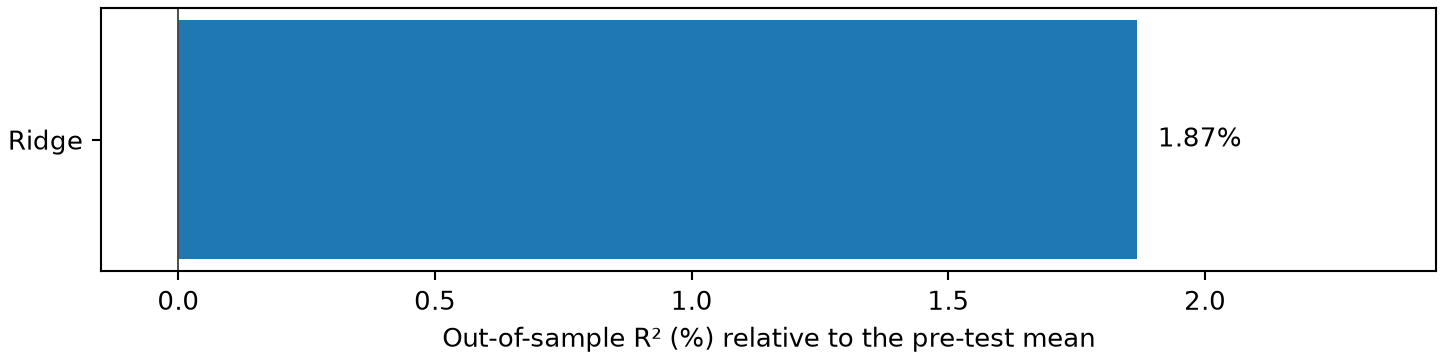

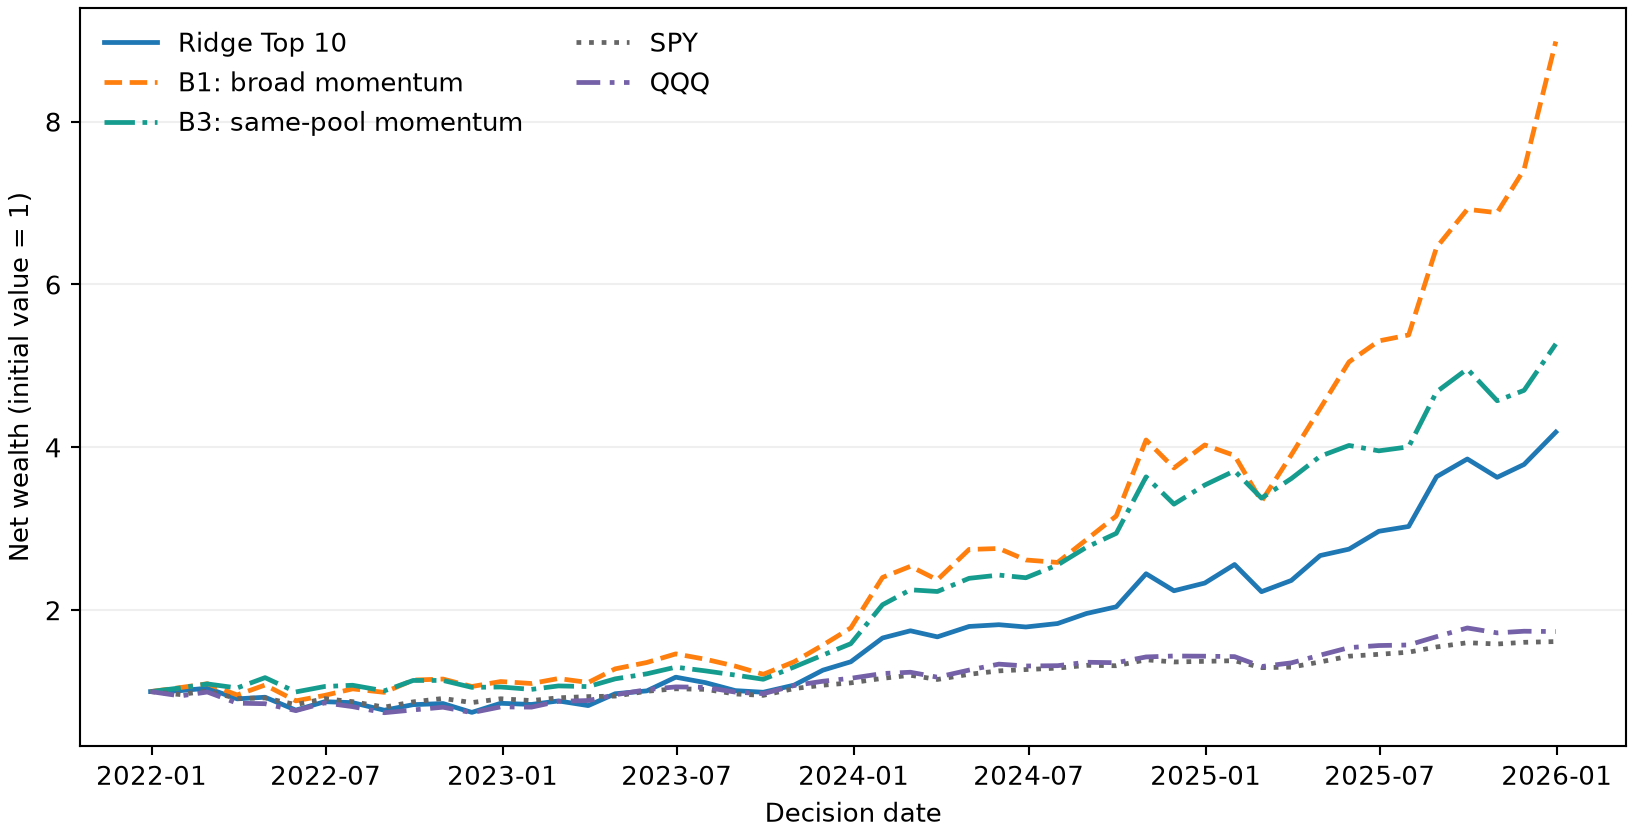

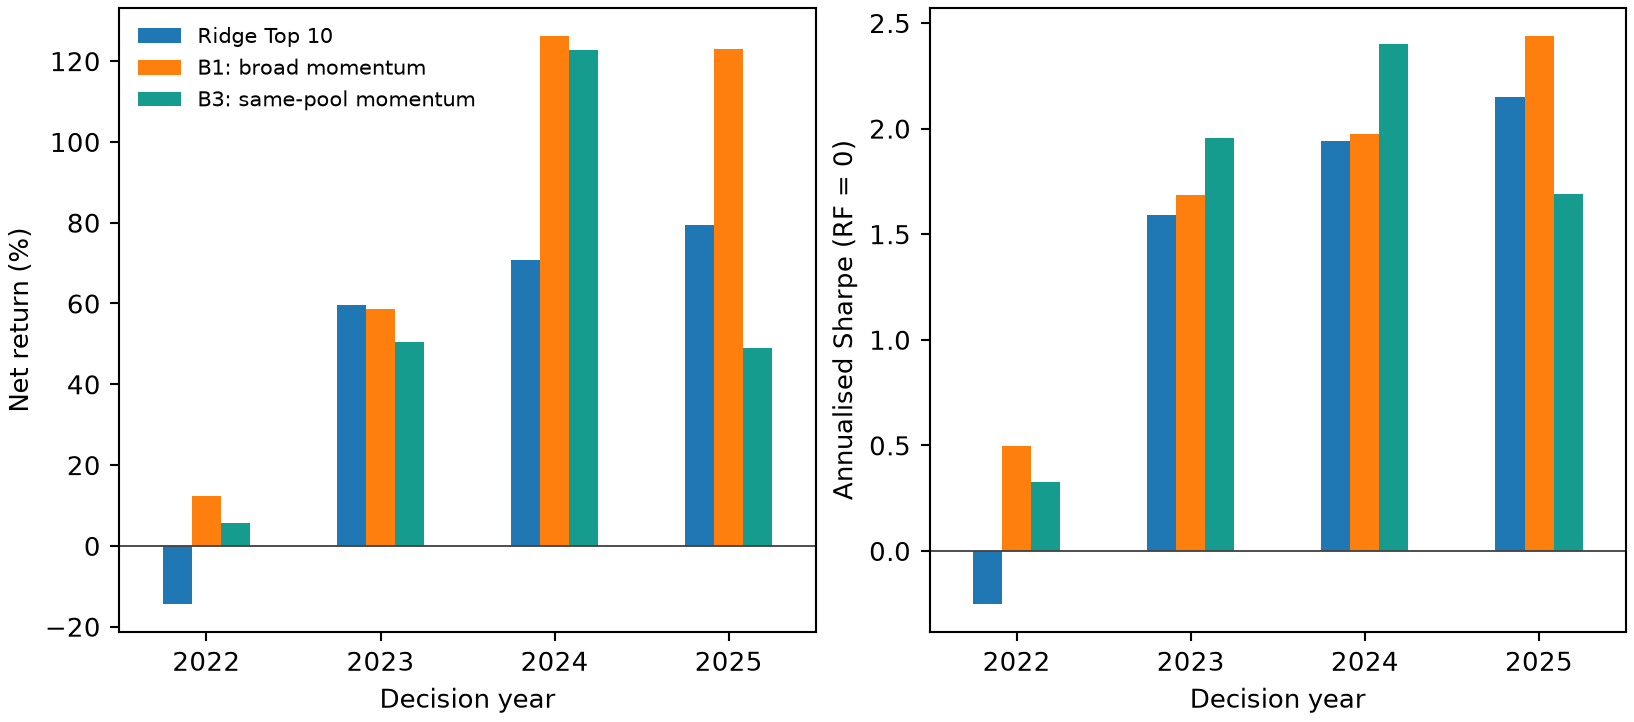

strategy,ridge,B1,B3,SPY,QQQ
decision_year,,,,,
2022,-14.36,12.33,5.63,-8.82,-18.79
2023,59.52,58.61,50.35,21.42,43.23
2024,70.77,126.14,122.68,23.86,23.34
2025,79.47,122.99,49.00,17.72,21.10


In [4]:
metrics, wide, annual, annual_sharpe, forecast = evaluate_ridge(cfg, decision)
display(pd.DataFrame([forecast])[["n_obs", "n_dates", "mse", "mae", "r2_oos_trainmean", "mean_rank_ic"]].round(6))
display(metrics[[
    "strategy", "annualized_return", "annualized_volatility", "sharpe_ratio", "max_drawdown", "average_turnover",
]].round(4))
plot_results(wide, annual, annual_sharpe, forecast, root / "figures")
for name in ["ridge_oos_r2.png", "ridge_benchmarks.png", "annual_returns_sharpe.png"]:
    display(Image(filename=str(root / "figures" / name), width=780))
display((100 * annual).round(2))

## 5. Test results

Ridge achieved a test Rank IC of 0.0619 and an out-of-sample R² of 0.0187 relative to the pre-test mean return. The Ridge portfolio earned a 43.04% net CAGR and a Sharpe ratio of 1.272 with a zero risk-free rate. B3 earned 51.51% and 1.590 with lower turnover. Ridge earned a higher net return than B3 in 2023 and 2025. B3 had the higher Sharpe in three of the four years.

The annual series groups returns by decision year, including the holding period that begins in January for a December decision. The four-year backtest uses a current-constituent universe, which exposes the active portfolios to survivorship and membership selection.